# AO simulation postprocessing

> !!! Batch saving not implemented !!!

In [ ]:
%matplotlib widget
import matplotlib.pyplot as plt
import h5py
import numpy as np
import pandas as pd
from matplotlib.patches import Circle
import os

GPU = True
MULTIGPU = True

DELETE_OLD_FILES = False

SMALL_SIZE = 20
MEDIUM_SIZE = 22
BIGGER_SIZE = 25
GPU = True
testDataDir = "output_prep/"
outputDir = "output_infer/"
inputDir = "output_ML/"


['auc', 'binary_accuracy', 'loss', 'val_auc', 'val_binary_accuracy', 'val_loss']
[33.15096694  2.34859084  2.21531007  2.14049092  2.10157588]
Epochs:  5


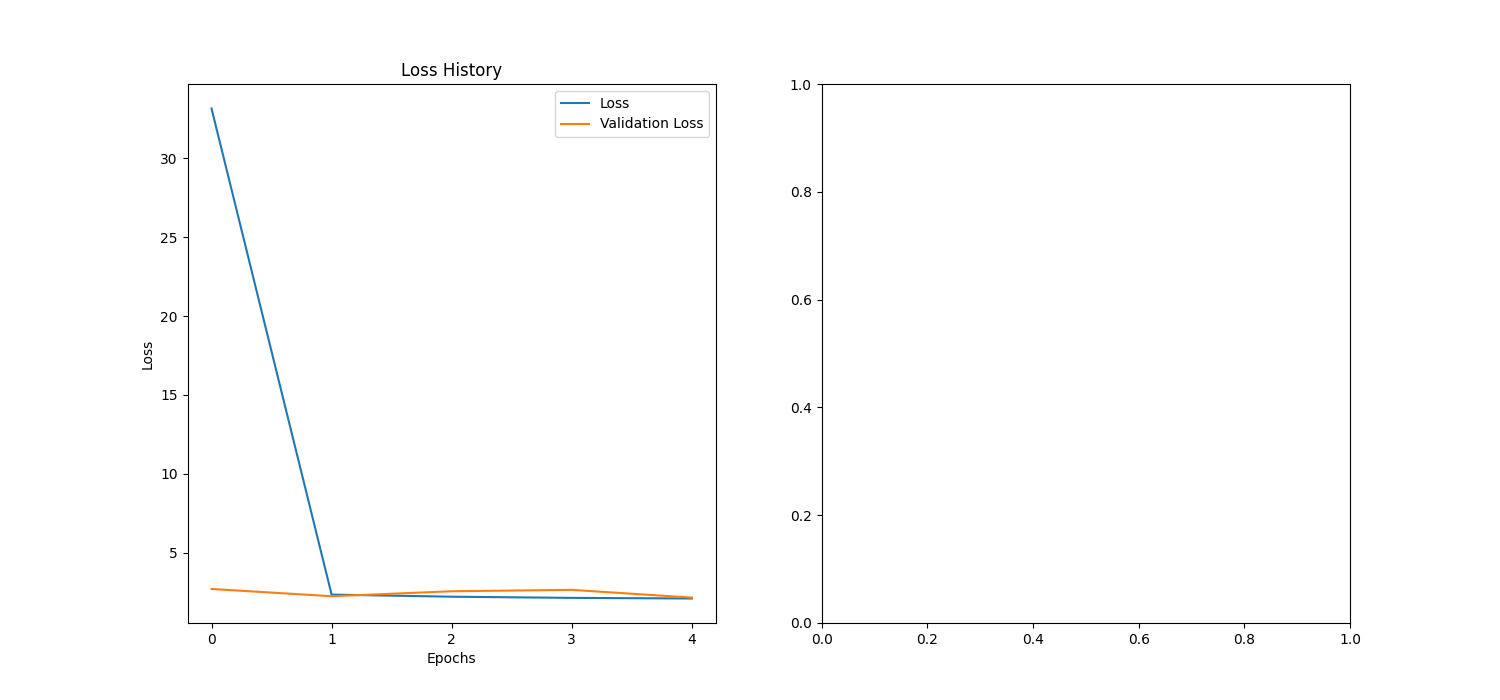

In [2]:
with h5py.File(inputDir+"history.h5", 'r') as history:
    key = list(history.keys())
    print(key)
    loss = history['loss'][()]
    print(history['loss'][()])
    val_loss = history['val_loss'][()]
    Epochs = len(loss)

print("Epochs: ", Epochs)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

ax1.plot(loss, "-", label="Loss")
ax1.plot(val_loss, "-", label="Validation Loss")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")
ax1.set_title("Loss History")
ax1.legend()

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=SMALL_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)

plt.savefig(outputDir + "/loss.png")

# Inference

## Rebuild model and load weights

In [12]:
import TM26_unet as unet
import torch
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda:0" if GPU and torch.cuda.is_available() else "cpu")
model = unet.build_unet(input_shape=(270,270, 1), n_channels_out=1).to(device) # input shape is (width, height, channel) where channel is WFSx and WFSy

if torch.cuda.device_count() > 1 and MULTIGPU:
    model = torch.nn.DataParallel(model)

lastCheckpoint = torch.load(inputDir + 'model.weights.pth', map_location=device, weights_only=True)
model.load_state_dict(lastCheckpoint)
model.eval()

DataParallel(
  (module): UNet(
    (inc): DoubleConv(
      (double_conv): Sequential(
        (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
      )
    )
    (down1): Down(
      (maxpool_conv): Sequential(
        (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (1): DoubleConv(
          (double_conv): Sequential(
            (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): ReLU(inplace=True)
            (3): Conv2d(128, 128, ker

## Load test data 

In [ ]:
with h5py.File(testDataDir+"ao_lightfield_test_1.h5", 'r') as temp:
    key = list(temp.keys())
    x_test = temp[key[0]][()][:]

with h5py.File(testDataDir+"ao_psf_test_1.h5", 'r') as temp:
    key = list(temp.keys())
    test_data = temp[key[0]][()][:]
    y_test = np.zeros((test_data.shape[0], 270, 270))
    for i in range(test_data.shape[0]):
        y_test[i] = unet.pixel_adder(test_data[i], final_shape=[270, 270])

n = x_test.shape[0]
predictions = np.zeros_like(y_test)

x_test_tens = torch.tensor(x_test, dtype=torch.float32).unsqueeze(1)

test_dataset = TensorDataset(torch.tensor(x_test, dtype=torch.float32))
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

## Infer

In [ ]:

with torch.no_grad():
    for batch_idx, (x_batch,) in enumerate(test_loader):
        x_batch = x_batch.unsqueeze(1).to(device)  # Add channel dim & move to GPU
        y_pred = model(x_batch)
        
        # Store predictions for this batch
        start_idx = batch_idx * 32
        end_idx = min(start_idx + 32, n)
        predictions[start_idx:end_idx] = y_pred.squeeze().cpu().numpy()

with h5py.File(outputDir+"predictions.h5", 'w') as f:
    f.create_dataset("predictions", data=predictions)